<a href="https://colab.research.google.com/github/francji1/01RAD/blob/main/HW/01RAD_Ex08_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01RAD - Homework 08: Robust regression, masking and the least weighted squares

The homework continues Exercise 08, Sections 5–6 (influence measures, masking, M-estimators, LTS).
- **Part A** (data): the Hawkins–Bradu–Kass data, where the classical diagnostics fail and robust methods do not.
- **Part B** (simulation): is the **least weighted squares** estimator (LWS) consistent, how efficient is it, and what happens with contaminated data?

Write a short answer in a markdown cell after each task: bullets, numbers from your output, your interpretation.

## Submission
**Individual work. Deadline: Sunday 29 November 2026, 23:59.** Fork `francji1/01RAD`, save your notebook into the `HW/` folder as `01RAD_Ex08_HW_<Surname>.ipynb` (without the brackets) and open a pull request to `main` that adds this one file only (details in `HW/README.md`). Python or R, as you prefer.

## Least weighted squares
- Order the squared residuals of a candidate $\mathbf{b}$: $r^2_{(1)}(\mathbf{b}) \le r^2_{(2)}(\mathbf{b}) \le \dots \le r^2_{(n)}(\mathbf{b})$.
- Choose weights $1 \ge w_1 \ge w_2 \ge \dots \ge w_n \ge 0$ that depend on the **rank** of the residual, not on the observation.
- LWS: $\widehat{\boldsymbol{\beta}}^{LWS} = \arg\min_{\mathbf{b}} \sum_{k=1}^{n} w_k\, r^2_{(k)}(\mathbf{b})$ (J. Á. Víšek).
- Special cases: all $w_k = 1$ is OLS; $w_k = 1$ for $k \le h$ and 0 otherwise is LTS (Exercise 08, Section 6.3).
- Smoothly decreasing weights keep more information than the hard cut of LTS (efficiency), the zero weights at the end keep the robustness (breakdown point about the share of zero weights).
- Algorithm as for LTS: random starts from $m+1$ points, then steps "order the residuals, assign the weights by rank, solve weighted least squares", repeated until $\mathbf{b}$ stops changing; keep the best of all starts.

Helper functions (`lts` as in Exercise 08, `lws` and a weight function) are given below. Use them, or write your own.

## Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import time

sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.precision', 4)
np.set_printoptions(precision=4, suppress=True)

In [ ]:
def influence_table(fit, labels):
    """h_ii, t_i, Cook, DFFITS, the largest |DFBETAS| and the rules of p. 132 (Exercise 08, Section 5.3)."""
    inf = fit.get_influence()
    n_, p_ = fit.model.exog.shape
    rows = fit.model.data.row_labels                         # index of the rows used in the fit
    rows = pd.RangeIndex(n_) if rows is None else rows
    if isinstance(labels, pd.Series):
        labels = labels.loc[rows]                            # works also for a fit on a subset of the rows
    dfb = pd.DataFrame(inf.dfbetas, columns=fit.model.exog_names, index=rows)
    tab = pd.DataFrame({'label': np.asarray(labels), 'h_ii': inf.hat_matrix_diag, 't_i': inf.resid_studentized_external,
                        'cook': inf.cooks_distance[0], 'dffits': inf.dffits[0],
                        'max|dfbetas|': dfb.abs().max(axis=1), 'for': dfb.abs().idxmax(axis=1)}, index=rows)
    tab['flag_h'] = tab['h_ii'] > 3 * p_ / n_
    tab['flag_cook'] = tab['cook'] > stats.f.ppf(0.5, p_, n_ - p_)
    tab['flag_dffits'] = tab['dffits'].abs() > 3 * np.sqrt(p_ / (n_ - p_))
    tab['flag_dfbetas'] = tab['max|dfbetas|'] > 1
    return tab


def lts(X, y, h=None, n_starts=500, seed=1):
    """Least trimmed squares: random elemental starts + C-steps (Exercise 08, Section 6.3).
    X includes the column of ones; h defaults to floor((n + m + 2) / 2)."""
    n_, p_ = X.shape
    h = h or (n_ + p_ + 1) // 2
    rng_ = np.random.default_rng(seed)
    best_obj, best_b = np.inf, None
    for _ in range(n_starts):
        idx = rng_.choice(n_, p_, replace=False)
        if abs(np.linalg.det(X[idx])) < 1e-12:
            continue
        b = np.linalg.solve(X[idx], y[idx])
        for _ in range(50):
            keep = np.argsort((y - X @ b) ** 2)[:h]
            b_new = np.linalg.lstsq(X[keep], y[keep], rcond=None)[0]
            if np.allclose(b_new, b):
                break
            b = b_new
        obj = np.sort((y - X @ b) ** 2)[:h].sum()
        if obj < best_obj:
            best_obj, best_b = obj, b
    return best_b


def weights_lws(n, g=0.5, h=0.75):
    """Weights by rank k = 1..n: 1 up to the rank g*n, then linearly down to 0 at the rank h*n, 0 after."""
    k = np.arange(1, n + 1) / n
    return np.clip((h - k) / (h - g), 0, 1)


def lws(X, y, w, n_starts=500, seed=1):
    """Least weighted squares: minimize sum_k w_k r^2_(k); random elemental starts + reweighting steps.
    w = non-increasing weights of length n (w[0] for the smallest squared residual)."""
    n_, p_ = X.shape
    sw = np.sqrt(w)
    rng_ = np.random.default_rng(seed)
    best_obj, best_b = np.inf, None
    for _ in range(n_starts):
        idx = rng_.choice(n_, p_, replace=False)
        if abs(np.linalg.det(X[idx])) < 1e-12:
            continue
        b = np.linalg.solve(X[idx], y[idx])
        for _ in range(50):
            order = np.argsort((y - X @ b) ** 2)               # observation order[k] gets the weight w[k]
            b_new = np.linalg.lstsq(X[order] * sw[:, None], y[order] * sw, rcond=None)[0]
            if np.allclose(b_new, b):
                break
            b = b_new
        obj = np.sort((y - X @ b) ** 2) @ w
        if obj < best_obj:
            best_obj, best_b = obj, b
    return best_b


plt.figure(figsize=(6, 3))
plt.plot(np.arange(1, 101), weights_lws(100), label='weights_lws(100): g = 0.5, h = 0.75')
plt.plot(np.arange(1, 101), (np.arange(1, 101) <= 52).astype(float), ls='--', label='LTS, h = 52')
plt.xlabel('rank $k$ of the squared residual'); plt.ylabel('$w_k$'); plt.legend(fontsize=8)
plt.show()

## Part A: the Hawkins–Bradu–Kass data
`HAWKINS.txt`: 75 observations, three regressors `x1`, `x2`, `x3` and the response `y` (artificial data of Hawkins, Bradu & Kass, 1984; R `robustbase::hbk`). Columns: observation number, `x1`, `x2`, `x3`, `y`.

In [3]:
url_hbk = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/HAWKINS.txt'
hbk = pd.read_csv(url_hbk, sep=r'\s+', header=None, names=['obs', 'x1', 'x2', 'x3', 'y'])
X_hbk = sm.add_constant(hbk[['x1', 'x2', 'x3']].to_numpy())
y_hbk = hbk['y'].to_numpy()
hbk.describe()

,obs,x1,x2,x3,y
count,75.0000,75.0000,75.0000,75.0000,75.0000
mean,38.0000,3.2067,5.5973,7.2307,1.2787
std,21.7945,3.6526,8.2391,11.7403,3.4928
min,1.0000,0.0000,0.0000,0.2000,-1.0000
25%,19.5000,0.8500,1.1000,0.9000,-0.4500
50%,38.0000,1.8000,2.2000,2.1000,0.1000
75%,56.5000,3.1000,3.2500,3.0000,0.7000
max,75.0000,12.0000,34.0000,37.0000,10.8000


### Task A1: look at the data
Draw the pairwise scatter plots (`sns.pairplot`) and $y$ against each regressor. What do you see? Can you guess from the plots alone which observations are unusual, and in which sense (in $\mathbf{x}$, in $y$, or both)?

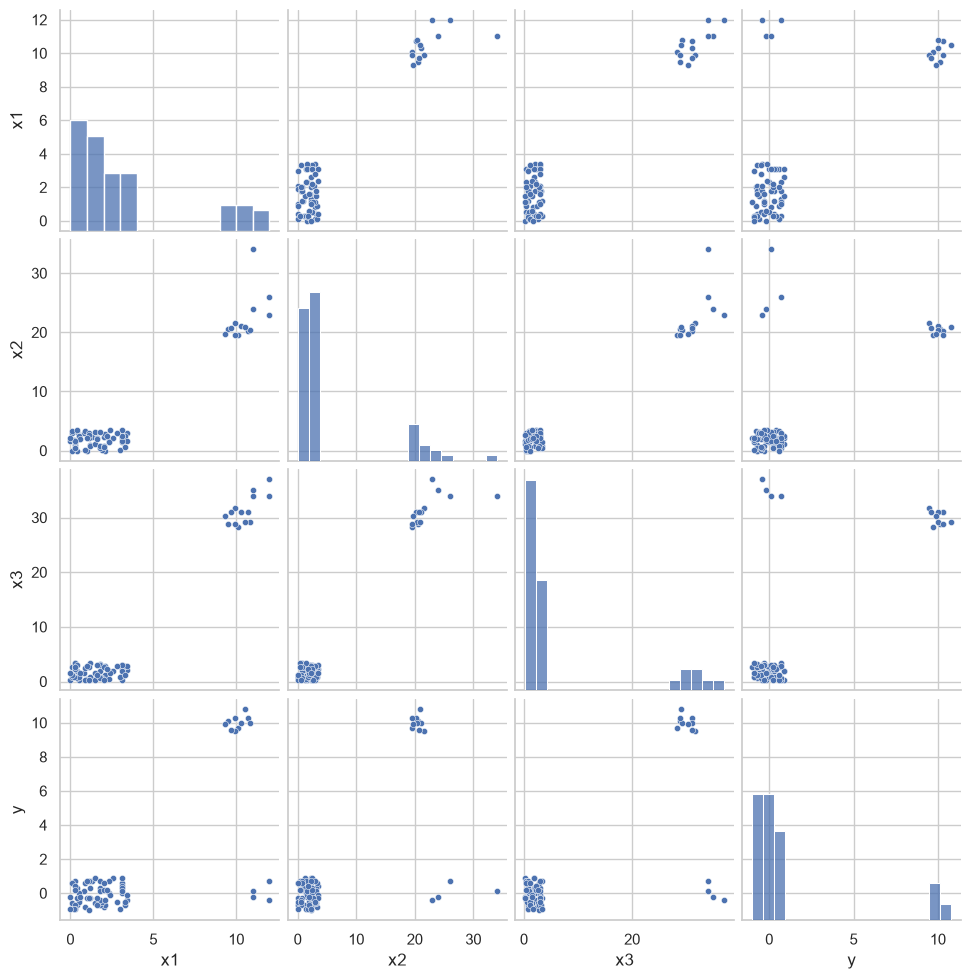

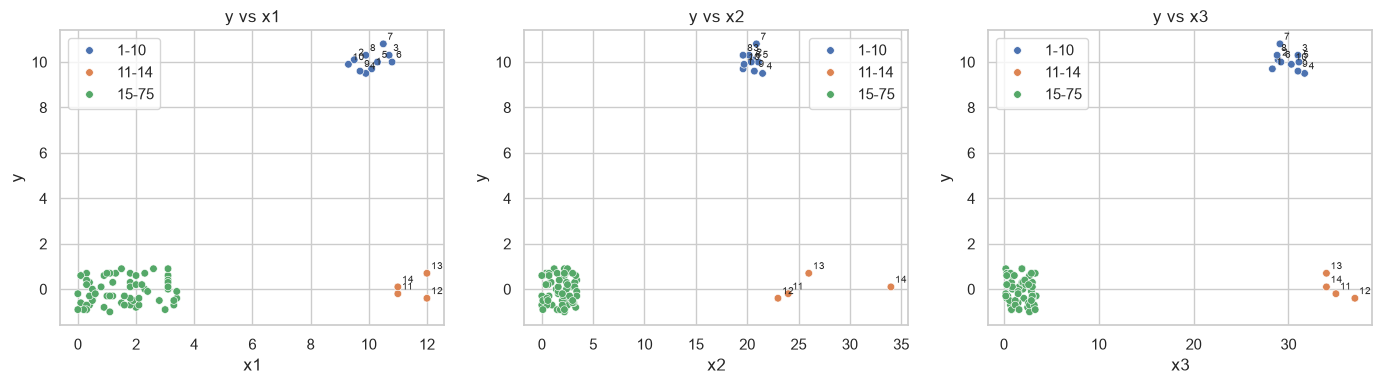

    obs    x1    x2    x3     y
0     1  10.1  19.6  28.3   9.7
1     2   9.5  20.5  28.9  10.1
2     3  10.7  20.2  31.0  10.3
3     4   9.9  21.5  31.7   9.5
4     5  10.3  21.1  31.1  10.0
5     6  10.8  20.4  29.2  10.0
6     7  10.5  20.9  29.1  10.8
7     8   9.9  19.6  28.8  10.3
8     9   9.7  20.7  31.0   9.6
9    10   9.3  19.7  30.3   9.9
10   11  11.0  24.0  35.0  -0.2
11   12  12.0  23.0  37.0  -0.4
12   13  12.0  26.0  34.0   0.7
13   14  11.0  34.0  34.0   0.1
14   15   3.4   2.9   2.1  -0.4
15   16   3.1   2.2   0.3   0.6


In [4]:
# A1
sns.pairplot(hbk[['x1', 'x2', 'x3', 'y']], diag_kind='hist', plot_kws={'s': 20})
plt.show()

# y against each regressor, observations 1-14 labelled
grp = np.where(hbk['obs'] <= 10, '1-10', np.where(hbk['obs'] <= 14, '11-14', '15-75'))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, v in zip(axes, ['x1', 'x2', 'x3']):
    sns.scatterplot(data=hbk, x=v, y='y', hue=grp, ax=ax, s=30)
    for i in range(14):
        ax.annotate(hbk['obs'][i], (hbk[v][i], hbk['y'][i]), fontsize=7, xytext=(3, 3), textcoords='offset points')
    ax.set_title(f'y vs {v}')
plt.tight_layout(); plt.show()

print(hbk.iloc[:16])

**Answer A1:**
- Most observations (15–75) form a compact cloud with $x_1, x_2, x_3 \in [0, 4]$ and $y$ around 0.
- Observations **1–14** are far from this cloud in all three regressors ($x_1 \approx 10$–12, $x_2 \approx 20$–34, $x_3 \approx 28$–37): they are unusual **in $\mathbf{x}$** (leverage points), and they move together in all three regressors.
- Within this group there are two different subgroups:
  - **1–10**: $y \approx 10$, far above the rest. They are unusual **in both $\mathbf{x}$ and $y$**, so they are outliers as well as leverage points.
  - **11–14**: $y \approx 0$, the same as the majority. They are unusual in $\mathbf{x}$ only, so they are only leverage points.
- In the plots of $y$ against $x_j$ the 14 points create an artificial strong positive "trend" (from the cloud at $y\approx 0$ up to the group at $y\approx 10$), but the majority of the data alone shows no relationship at all.

### Task A2: OLS and the classical diagnostics
Fit `y ~ x1 + x2 + x3` by OLS. Check the residual plots, then compute the influence measures of Exercise 08 (`influence_table`) and the Bonferroni test of outliers (`outlier_test`).
1. Which observations does each rule flag?
2. Which observations have the largest $|\widehat{t}_i|$, and which the largest $h_{ii}$?
3. Is any regression coefficient significant? What would you conclude about the data from OLS and its diagnostics alone?

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.602
Model:                            OLS   Adj. R-squared:                  0.585
Method:                 Least Squares   F-statistic:                     35.77
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           3.38e-14
Time:                        19:18:32   Log-Likelihood:                -165.19
No. Observations:                  75   AIC:                             338.4
Df Residuals:                      71   BIC:                             347.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.3875      0.416     -0.930      0.3

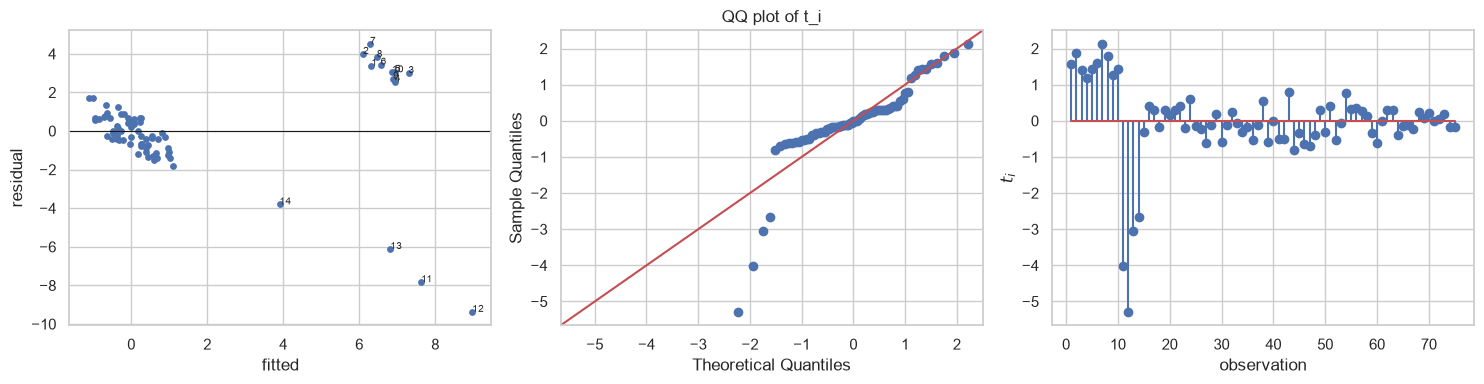

Observations flagged by each rule:
  flag_h        [14]
  flag_cook     [12, 14]
  flag_dffits   [11, 12, 13, 14]
  flag_dfbetas  [12, 14]

Flagged by at least one rule:


,label,h_ii,t_i,cook,dffits,max|dfbetas|,for,flag_h,flag_cook,flag_dffits,flag_dfbetas
10,11,0.0942,-4.0303,0.3478,-1.2999,0.4905,x3,False,False,True,False
11,12,0.1439,-5.2872,0.8514,-2.1676,1.2615,x3,False,True,True,True
12,13,0.1091,-3.0437,0.2541,-1.0652,0.4235,x2,False,False,True,False
13,14,0.5637,-2.6660,2.1137,-3.0302,2.7946,x2,True,True,True,True



Largest |t_i|:


,label,h_ii,t_i,cook
11,12,0.1439,-5.2872,0.8514
10,11,0.0942,-4.0303,0.3478
12,13,0.1091,-3.0437,0.2541
13,14,0.5637,-2.6660,2.1137
6,7,0.0680,2.1285,0.0787
1,2,0.0599,1.8627,0.0534


Largest h_ii (rule 3p/n = 0.160):


,label,h_ii,t_i,cook
13,14,0.5637,-2.6660,2.1137
11,12,0.1439,-5.2872,0.8514
12,13,0.1091,-3.0437,0.2541
10,11,0.0942,-4.0303,0.3478
9,10,0.0869,1.4233,0.0475
2,3,0.0857,1.4051,0.0456


Bonferroni outlier test (smallest p-values):


,student_resid,unadj_p,bonf(p)
obs,,,
12,-5.2872,1.3450e-06,0.0001
11,-4.0303,1.3975e-04,0.0105
13,-3.0437,3.2907e-03,0.2468
14,-2.6660,9.5247e-03,0.7144
1,1.5678,1.2143e-01,1.0000
2,1.8627,6.6706e-02,1.0000


In [5]:
# A2
ols = smf.ols('y ~ x1 + x2 + x3', data=hbk).fit()
print(ols.summary())

# residual plots
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(ols.fittedvalues, ols.resid, s=15)
axes[0].axhline(0, color='k', lw=0.8); axes[0].set_xlabel('fitted'); axes[0].set_ylabel('residual')
for i in range(14):
    axes[0].annotate(i + 1, (ols.fittedvalues[i], ols.resid[i]), fontsize=7)
sm.qqplot(ols.get_influence().resid_studentized_external, line='45', ax=axes[1]); axes[1].set_title('QQ plot of t_i')
axes[2].stem(hbk['obs'], ols.get_influence().resid_studentized_external)
axes[2].set_xlabel('observation'); axes[2].set_ylabel('$t_i$')
plt.tight_layout(); plt.show()

tab = influence_table(ols, hbk['obs'])
flags = ['flag_h', 'flag_cook', 'flag_dffits', 'flag_dfbetas']
print('Observations flagged by each rule:')
for f in flags:
    print(f'  {f:13s}', tab.loc[tab[f], 'label'].tolist())
print('\nFlagged by at least one rule:')
display(tab[tab[flags].any(axis=1)])
print('\nLargest |t_i|:')
display(tab.reindex(tab['t_i'].abs().sort_values(ascending=False).index).head(6)[['label', 'h_ii', 't_i', 'cook']])
print('Largest h_ii (rule 3p/n = %.3f):' % (3 * 4 / 75))
display(tab.sort_values('h_ii', ascending=False).head(6)[['label', 'h_ii', 't_i', 'cook']])

ot = ols.outlier_test()            # Bonferroni outlier test
ot.index = hbk['obs']
print('Bonferroni outlier test (smallest p-values):')
display(ot.sort_values('bonf(p)').head(6))

**Answer A2:**
1. Flags by rule (OLS, $p = 4$, $n = 75$):
   - $h_{ii} > 3p/n = 0.16$: only **14** ($h_{14,14} = 0.56$),
   - Cook's distance $> F_{0.5}(p, n-p)$: **12, 14**,
   - $|\mathrm{DFFITS}| > 3\sqrt{p/(n-p)}$: **11, 12, 13, 14**,
   - $\max|\mathrm{DFBETAS}| > 1$: **12, 14**.
   - Bonferroni outlier test: significant at 5 % only for **12** ($p_{\text{bonf}} = 0.0001$) and **11** ($p_{\text{bonf}} = 0.011$). For 13 and 14 it is not significant ($p_{\text{bonf}} = 0.25, 0.71$).
2. Largest $|\widehat t_i|$: 12 ($-5.29$), 11 ($-4.03$), 13 ($-3.04$), 14 ($-2.67$). Largest $h_{ii}$: 14 (0.56), 12 (0.14), 13 (0.11), 11 (0.09). Observations **1–10** have small leverages ($h_{ii} \approx 0.06$–0.09) and small residuals ($|t_i| < 2.2$), so no rule flags them.
3. $x_2$ ($p = 0.034$, *negative* coefficient $-0.33$) and $x_3$ ($p = 0.004$) are significant, $R^2 = 0.60$, overall F-test $p \approx 10^{-14}$. The residuals are clearly non-normal (skew $-1.5$, kurtosis 8.5, Jarque–Bera $p \approx 10^{-27}$).
   - From OLS alone I would conclude that $y$ depends on $x_2$ and $x_3$ and that observations 11–14 are outliers / influential points that should be examined or removed.

### Task A3: M-estimators
Fit Huber and Tukey (`sm.RLM(y, X, M=sm.robust.norms.HuberT())`, `TukeyBiweight()`, both started from OLS).
1. Compare the coefficients with OLS.
2. Which observations get weights below 0.5? Are they the same as those flagged in A2?
3. Explain the result with the property of M-estimators discussed in Exercise 08, Section 6.2.

,OLS,Huber,Tukey
const,-0.3875,-0.7799,-0.9459
x1,0.2392,0.1664,0.1449
x2,-0.3345,0.0119,0.1974
x3,0.3833,0.2721,0.1803


Huber weights < 0.5: [11, 12, 13, 14]
Tukey weights < 0.5: [11, 12, 13, 14]


,obs,w_Huber,w_Tukey
0,1,1.0000,0.9939
1,2,1.0000,0.9770
2,3,1.0000,0.9980
3,4,1.0000,0.8833
4,5,1.0000,0.9866
5,6,1.0000,0.9989
6,7,0.7221,0.9040
7,8,0.8829,0.9252
8,9,1.0000,0.9622
9,10,1.0000,0.9970


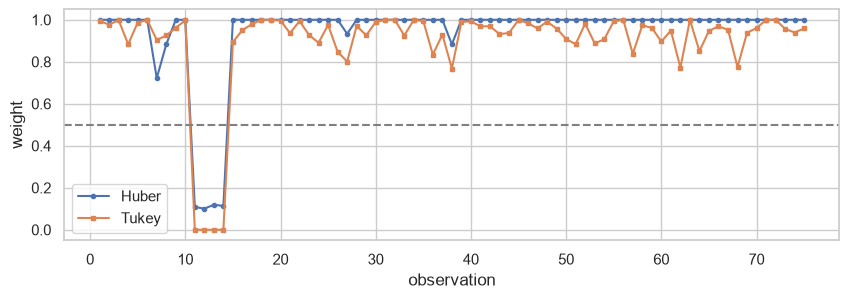

In [6]:
# A3
huber = sm.RLM(y_hbk, X_hbk, M=sm.robust.norms.HuberT()).fit()          # IRLS started from OLS
tukey = sm.RLM(y_hbk, X_hbk, M=sm.robust.norms.TukeyBiweight()).fit()
names = ['const', 'x1', 'x2', 'x3']
coef_A3 = pd.DataFrame({'OLS': ols.params.values, 'Huber': huber.params, 'Tukey': tukey.params}, index=names)
display(coef_A3)

w_A3 = pd.DataFrame({'obs': hbk['obs'], 'w_Huber': huber.weights, 'w_Tukey': tukey.weights})
print('Huber weights < 0.5:', w_A3.loc[w_A3.w_Huber < 0.5, 'obs'].tolist())
print('Tukey weights < 0.5:', w_A3.loc[w_A3.w_Tukey < 0.5, 'obs'].tolist())
display(w_A3.iloc[:16])

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(hbk['obs'], huber.weights, 'o-', ms=3, label='Huber')
ax.plot(hbk['obs'], tukey.weights, 's-', ms=3, label='Tukey')
ax.axhline(0.5, color='grey', ls='--'); ax.set_xlabel('observation'); ax.set_ylabel('weight'); ax.legend()
plt.show()

**Answer A3:**
1. Huber $(-0.78, 0.17, 0.01, 0.27)$ and Tukey $(-0.95, 0.14, 0.20, 0.18)$ differ from OLS $(-0.39, 0.24, -0.33, 0.38)$ mainly in $x_2$, which changes sign. But they still have a clearly positive slope for $x_3$ and do not describe the majority of the data (A4).
2. Weights below 0.5 (both Huber and Tukey): **11, 12, 13, 14**. Tukey even gives them weight 0. Observations 1–10 get weights close to 1. These are exactly the observations flagged in A2: the M-estimators "agree" with the OLS diagnostics.
3. Explanation: M-estimators downweight observations with **large residuals** only. They are robust against outliers in $y$ but **not against leverage points** (bounded influence in $y$, unbounded in $\mathbf{x}$; breakdown point $1/n \to 0$). Here the 10 outlier leverage points 1–10 pull the starting OLS fit towards themselves, so their own residuals are small and they keep weight $\approx 1$. The leverage points 11–14 then look like outliers and are downweighted. Starting the IRLS from OLS, the M-estimator only finds the nearest local solution, which is the one "contaminated" by 1–10.

### Task A4: high-breakdown estimators
Fit LTS (`lts`), LWS (`lws` with `weights_lws(75)`) and Tukey started from LTS (`sm.RLM(..., M=sm.robust.norms.TukeyBiweight()).fit(start_params=b_lts, update_scale=False)`).
1. Compare the coefficients of all fits (OLS, Huber, Tukey, LTS, LWS, Tukey from LTS) in one table.
2. **Robust diagnostic plot**: residuals of the LTS fit divided by a robust scale ($\mathrm{MAD} = \mathrm{median}\,|r_i| / 0.6745$, or the scale of the Tukey fit) against $h_{ii}$ of the OLS fit (or against the Mahalanobis distance of $\mathbf{x}_i$). Mark the horizontal lines $\pm 2.5$.
3. Sort the observations into four groups: regular, **vertical outliers** (unusual $y$ only), **good leverage points** (unusual $\mathbf{x}$, $y$ follows the model of the majority), **bad leverage points** (unusual $\mathbf{x}$ and $y$ off the model).
4. Refit OLS without the bad leverage points. Compare with the robust fits and look at its residual plots.

1.6 s


,OLS,Huber,Tukey,LTS,LWS,Tukey from LTS
const,-0.3875,-0.7799,-0.9459,-0.6115,-0.5430,-0.1929
x1,0.2392,0.1664,0.1449,0.2549,0.2156,0.0867
x2,-0.3345,0.0119,0.1974,0.0479,0.0544,0.0414
x3,0.3833,0.2721,0.1803,-0.1058,-0.0966,-0.0544


MAD scale of the LTS residuals: 0.689, cut-off for distances: sqrt(chi2_3(0.975)) = 3.06


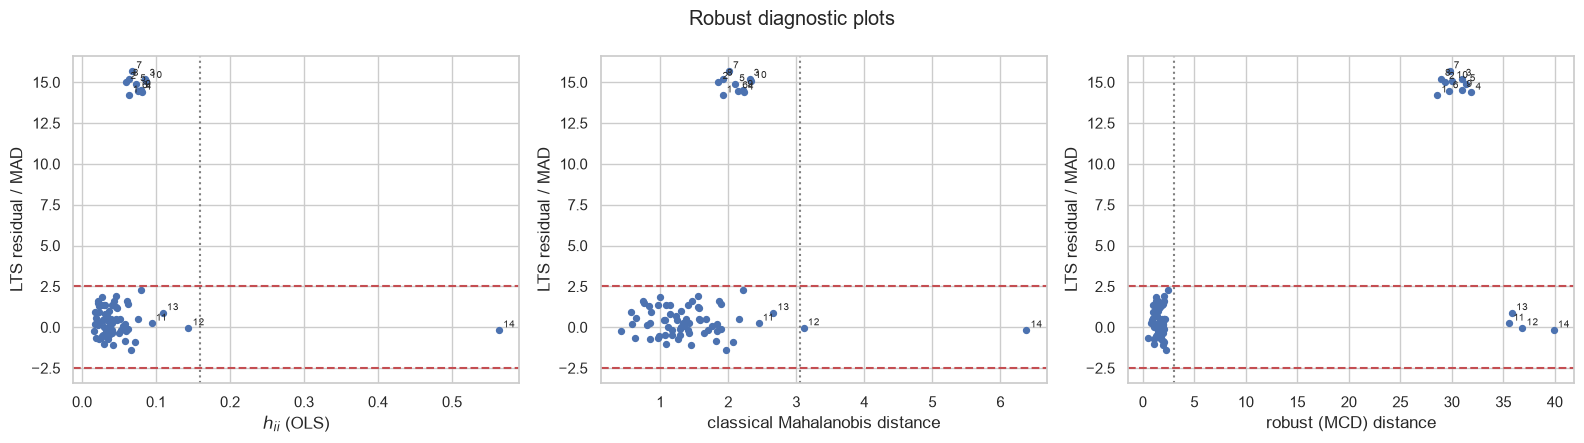

vertical outlier : []
good leverage    : [11, 12, 13, 14]
bad leverage     : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
regular          : 61 observations


,obs,z_LTS,h_ii,MD,RD,group
0,1,14.2029,0.0630,1.9168,28.5862,bad leverage
1,2,15.0344,0.0599,1.8558,29.3271,bad leverage
2,3,15.2239,0.0857,2.3137,30.9635,bad leverage
3,4,14.3765,0.0805,2.2297,31.9065,bad leverage
4,5,14.8895,0.0729,2.1001,31.3392,bad leverage
5,6,14.4618,0.0756,2.1462,29.6997,bad leverage
6,7,15.6829,0.0680,2.0105,29.7885,bad leverage
7,8,15.2238,0.0631,1.9193,28.9329,bad leverage
8,9,14.5436,0.0800,2.2212,31.0245,bad leverage
9,10,15.0886,0.0869,2.3335,30.0431,bad leverage


                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.1805      0.104     -1.728      0.089      -0.389       0.028
x1             0.0814      0.067      1.221      0.227      -0.052       0.215
x2             0.0399      0.040      0.986      0.328      -0.041       0.121
x3            -0.0517      0.035     -1.461      0.149      -0.122       0.019


,OLS,Huber,Tukey,LTS,LWS,Tukey from LTS,OLS w/o bad lev.
const,-0.3875,-0.7799,-0.9459,-0.6115,-0.5430,-0.1929,-0.1805
x1,0.2392,0.1664,0.1449,0.2549,0.2156,0.0867,0.0814
x2,-0.3345,0.0119,0.1974,0.0479,0.0544,0.0414,0.0399
x3,0.3833,0.2721,0.1803,-0.1058,-0.0966,-0.0544,-0.0517


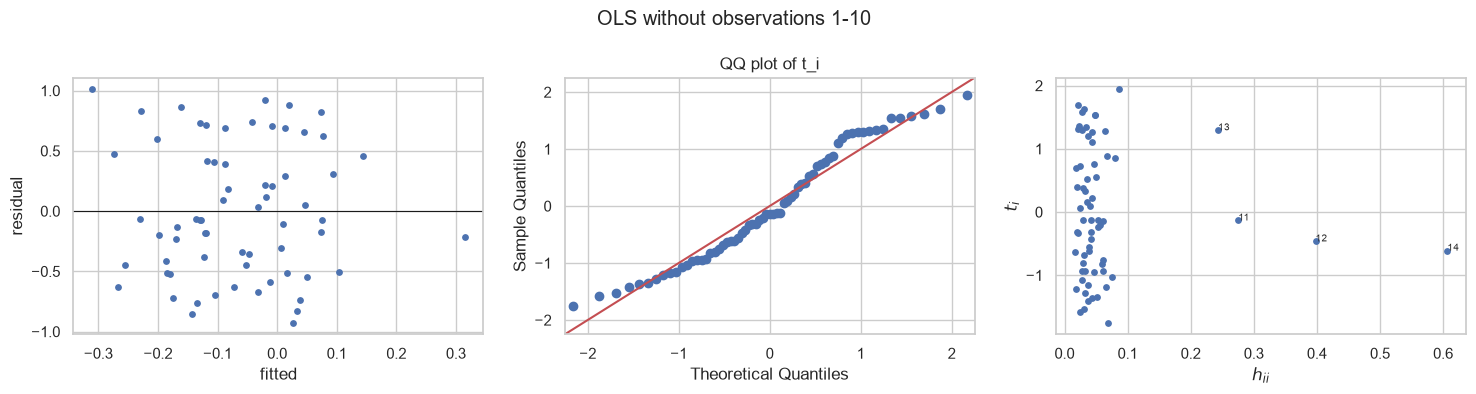

Flags in the refit: {'flag_h': [11, 12, 13, 14], 'flag_cook': [], 'flag_dffits': [], 'flag_dfbetas': []}


In [7]:
# A4
from sklearn.covariance import MinCovDet

t0 = time.time()
b_lts = lts(X_hbk, y_hbk)                                   # h = (75 + 4 + 1) // 2 = 40
b_lws = lws(X_hbk, y_hbk, weights_lws(75))
tukey_lts = sm.RLM(y_hbk, X_hbk, M=sm.robust.norms.TukeyBiweight()).fit(start_params=b_lts, update_scale=False)
print(f'{time.time() - t0:.1f} s')

# 1. all coefficients in one table
coef_all = coef_A3.assign(LTS=b_lts, LWS=b_lws, **{'Tukey from LTS': tukey_lts.params})
display(coef_all)

# 2. robust diagnostic plot
r_lts = y_hbk - X_hbk @ b_lts
s_mad = np.median(np.abs(r_lts)) / 0.6745
z = r_lts / s_mad                                            # standardized LTS residuals
h_ols = tab['h_ii'].to_numpy()
Xr = hbk[['x1', 'x2', 'x3']].to_numpy()
md_classic = np.sqrt(((Xr - Xr.mean(0)) @ np.linalg.inv(np.cov(Xr.T)) * (Xr - Xr.mean(0))).sum(1))
md_robust = np.sqrt(MinCovDet(random_state=0).fit(Xr).mahalanobis(Xr))   # robust distance (MCD)
cut_md = np.sqrt(stats.chi2.ppf(0.975, 3))
print(f'MAD scale of the LTS residuals: {s_mad:.3f}, cut-off for distances: sqrt(chi2_3(0.975)) = {cut_md:.2f}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, xv, lab, cut in zip(axes, [h_ols, md_classic, md_robust],
                            ['$h_{ii}$ (OLS)', 'classical Mahalanobis distance', 'robust (MCD) distance'],
                            [3 * 4 / 75, cut_md, cut_md]):
    ax.scatter(xv, z, s=18)
    for i in range(14):
        ax.annotate(i + 1, (xv[i], z[i]), fontsize=7, xytext=(3, 2), textcoords='offset points')
    ax.axhline(2.5, color='r', ls='--'); ax.axhline(-2.5, color='r', ls='--'); ax.axvline(cut, color='grey', ls=':')
    ax.set_xlabel(lab); ax.set_ylabel('LTS residual / MAD')
plt.suptitle('Robust diagnostic plots'); plt.tight_layout(); plt.show()

# 3. four groups (robust residual |z| > 2.5, leverage = robust distance > cut-off)
lev = md_robust > cut_md
out = np.abs(z) > 2.5
group = np.select([~lev & ~out, ~lev & out, lev & ~out, lev & out],
                  ['regular', 'vertical outlier', 'good leverage', 'bad leverage'], default='regular')
diag = pd.DataFrame({'obs': hbk['obs'], 'z_LTS': z, 'h_ii': h_ols, 'MD': md_classic, 'RD': md_robust, 'group': group})
for g in ['vertical outlier', 'good leverage', 'bad leverage']:
    print(f'{g:17s}:', diag.loc[diag.group == g, 'obs'].tolist())
print('regular          :', (diag.group == 'regular').sum(), 'observations')
display(diag.iloc[:16])

# 4. OLS without the bad leverage points
bad = diag.group == 'bad leverage'
ols_clean = smf.ols('y ~ x1 + x2 + x3', data=hbk[~bad]).fit()
print(ols_clean.summary().tables[1])
coef_all['OLS w/o bad lev.'] = ols_clean.params.values
display(coef_all)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(ols_clean.fittedvalues, ols_clean.resid, s=15); axes[0].axhline(0, color='k', lw=.8)
axes[0].set_xlabel('fitted'); axes[0].set_ylabel('residual')
sm.qqplot(ols_clean.get_influence().resid_studentized_external, line='45', ax=axes[1]); axes[1].set_title('QQ plot of t_i')
inf_c = ols_clean.get_influence()
axes[2].scatter(inf_c.hat_matrix_diag, inf_c.resid_studentized_external, s=15)
for i, o in enumerate(hbk.loc[~bad, 'obs']):
    if o <= 14:
        axes[2].annotate(o, (inf_c.hat_matrix_diag[i], inf_c.resid_studentized_external[i]), fontsize=7)
axes[2].set_xlabel('$h_{ii}$'); axes[2].set_ylabel('$t_i$')
plt.suptitle('OLS without observations 1-10'); plt.tight_layout(); plt.show()
tab_clean = influence_table(ols_clean, hbk['obs'])
print('Flags in the refit:', {f: tab_clean.loc[tab_clean[f], 'label'].tolist() for f in flags})

**Answer A4:**
1. Coefficients (table above):

| | const | $x_1$ | $x_2$ | $x_3$ |
|---|---|---|---|---|
| OLS | −0.39 | 0.24 | −0.33 | 0.38 |
| Huber | −0.78 | 0.17 | 0.01 | 0.27 |
| Tukey | −0.95 | 0.14 | 0.20 | 0.18 |
| LTS | −0.61 | 0.25 | 0.05 | −0.11 |
| LWS | −0.54 | 0.22 | 0.05 | −0.10 |
| Tukey from LTS | −0.19 | 0.09 | 0.04 | −0.05 |
| OLS without 1–10 | −0.18 | 0.08 | 0.04 | −0.05 |

   LTS, LWS and Tukey started from LTS all give slopes close to **0**, i.e. for the majority of the data $y$ does not depend on $x_1, x_2, x_3$. Tukey from LTS (a high-breakdown start + an efficient M-step, i.e. an MM-type estimator) is almost identical to OLS without 1–10.

2. Robust diagnostic plot: the LTS residuals divided by $\mathrm{MAD} = 0.69$, plotted against (a) $h_{ii}$ of OLS, (b) the classical Mahalanobis distance, (c) the robust MCD distance.
   - Observations **1–10** have standardized LTS residuals of **14–16**, far beyond $\pm 2.5$.
   - Against $h_{ii}$ of OLS and against the classical distance they do **not** look like leverage points ($h_{ii} \approx 0.06$–0.09, $MD \approx 1.9$–2.3). The classical distance is itself masked by the group of 14 points (they inflate the mean and covariance).
   - Only the robust distance ($RD \approx 29$–40 vs. the cut-off $\sqrt{\chi^2_3(0.975)} = 3.06$) shows all 14 points as leverage points.
3. Groups:
   - **bad leverage points (outliers): 1–10** (large robust distance, $|z| \approx 15$),
   - **good leverage points: 11–14** (large robust distance, $|z| < 1$, they follow the model of the majority),
   - **vertical outliers: none**,
   - **regular: 15–75** (61 observations).
4. OLS without 1–10: $(-0.18, 0.08, 0.04, -0.05)$, **no coefficient significant** (all $p > 0.08$). The fit is very close to Tukey from LTS and similar to LTS/LWS (LTS/LWS use only part of the data, so they are noisier). The residual plots look fine: no structure, and the QQ plot is close to the line. In the refit only $h_{ii}$ flags 11–14 (they are still far in $\mathbf{x}$), but Cook, DFFITS and DFBETAS flag nothing. They are good leverage points: they only make the estimates more precise.

 ### Task A5: masking and swamping
In 3–5 sentences: which observations did the OLS diagnostics flag **wrongly** (swamping) and which did they **miss** (masking)? Why? What would have happened if you had deleted the points flagged in A2 and refitted?

**Answer A5:**
- **Swamping:** the OLS diagnostics flagged **11–14** (Cook, DFFITS, DFBETAS, Bonferroni for 11 and 12), although these are *good* leverage points that follow the model of the majority.
- **Masking:** they **missed 1–10**, the real bad leverage points. Because 10 of them form a cluster, they pull the OLS fit towards themselves (small residuals). Together they inflate the mean and covariance of $\mathbf{X}$ (small $h_{ii}$ and classical Mahalanobis distance). Deleting one of them changes almost nothing, because the other nine hold the fit there, so leave-one-out measures (Cook, DFFITS, DFBETAS, $t_i$) cannot see them.
- If we deleted the flagged points 11–14 and refitted, the fit would be determined even more by 1–10. The new diagnostics would show nothing alarming, and we would "confirm" a wrong model with a strong dependence of $y$ on the regressors, after throwing away the good observations. That is why a single-case diagnostic should be checked against a high-breakdown fit (LTS/LWS) and robust distances.

## Part B: consistency and efficiency of LWS (simulation)

Model with $m = 4$ regressors and $\boldsymbol{\beta} = (2, 3, -2, 2, 3)^T$:
- column 1: ones (intercept),
- column 2: $\mathrm{Bi}(10, 0.3) + 1$,
- column 3: $N(10, 2^2)$,
- column 4: $N(20, 3^2)$,
- column 5: exponential with mean 8,
- errors $e_i \sim N(0, 1)$, a new $\mathbf{X}$ in every data set.

The function below generates one data set. `eps` is the share of contaminated observations; the contamination is up to you (Task B3), two simple examples are given.

In [8]:
beta_true = np.array([2.0, 3.0, -2.0, 2.0, 3.0])


def generate(n, rng, eps=0.0, kind='vertical'):
    """One data set of the simulation; the first round(eps * n) observations are contaminated."""
    X = np.column_stack([np.ones(n), rng.binomial(10, 0.3, n) + 1, rng.normal(10, 2, n),
                         rng.normal(20, 3, n), rng.exponential(8, n)])
    y = X @ beta_true + rng.normal(0, 1, n)
    k = int(round(eps * n))
    if k > 0 and kind == 'vertical':          # outliers in y only
        y[:k] += rng.normal(30, 5, k)
    if k > 0 and kind == 'leverage':          # bad leverage points: x5 far away, y generated from the original x
        X[:k, 4] = rng.normal(80, 5, k)
    return X, y


rng = np.random.default_rng(2026)
X_demo, y_demo = generate(200, rng, eps=0.1, kind='leverage')
t0 = time.time()
print('OLS:', np.linalg.lstsq(X_demo, y_demo, rcond=None)[0])
print('LTS:', lts(X_demo, y_demo, n_starts=100))
print('LWS:', lws(X_demo, y_demo, weights_lws(200), n_starts=100))
print(f'{time.time() - t0:.1f} s')

OLS: [15.9295  4.0951 -1.908   2.0535  0.4304]
LTS: [ 0.5269  3.1195 -1.8496  1.9889  2.9795]


LWS: [ 1.1062  3.1196 -1.8487  1.9656  2.9757]
0.5 s


### Task B1: your own weight function
Write `weights2(n, g, h)` for $0 < g < h < 1$:
- on the ranks $k \le gn$ the weights decrease linearly from 1 to 0.9,
- on $gn < k \le hn$ they decrease linearly from 0.9 to 0,
- for $k > hn$ they are 0.

Plot it next to `weights_lws`. Fit LWS with `weights2` on the Hawkins–Bradu–Kass data (for example $g = 0.6$, $h = 0.8$) and compare with A4. What is the largest share of contamination such a weight function can, in principle, survive?

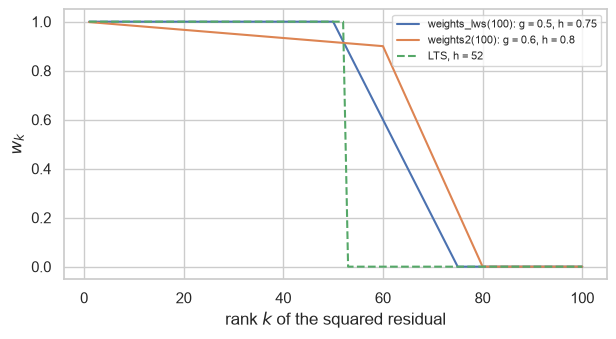

,OLS,LTS,LWS,LWS weights2,Tukey from LTS,OLS w/o bad lev.
const,-0.3875,-0.6115,-0.5430,-0.4644,-0.1929,-0.1805
x1,0.2392,0.2549,0.2156,0.1726,0.0867,0.0814
x2,-0.3345,0.0479,0.0544,0.0553,0.0414,0.0399
x3,0.3833,-0.1058,-0.0966,-0.0850,-0.0544,-0.0517


Observations with zero weight in LWS(weights2): [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 21, 38, 43, 53, 68, 70]
Zero weights: 16 of 75 = 21 %


In [9]:
# B1
def weights2(n, g=0.6, h=0.8):
    """1 -> 0.9 linearly on ranks k <= g*n, 0.9 -> 0 linearly on g*n < k <= h*n, 0 for k > h*n."""
    assert 0 < g < h < 1
    k = np.arange(1, n + 1) / n
    return np.where(k <= g, 1 - 0.1 * k / g, np.where(k <= h, 0.9 * (h - k) / (h - g), 0.0))


ranks = np.arange(1, 101)
plt.figure(figsize=(7, 3.5))
plt.plot(ranks, weights_lws(100), label='weights_lws(100): g = 0.5, h = 0.75')
plt.plot(ranks, weights2(100, 0.6, 0.8), label='weights2(100): g = 0.6, h = 0.8')
plt.plot(ranks, (ranks <= 52).astype(float), ls='--', label='LTS, h = 52')
plt.xlabel('rank $k$ of the squared residual'); plt.ylabel('$w_k$'); plt.legend(fontsize=8); plt.show()

b_lws2 = lws(X_hbk, y_hbk, weights2(75, 0.6, 0.8))
coef_all['LWS weights2'] = b_lws2
display(coef_all[['OLS', 'LTS', 'LWS', 'LWS weights2', 'Tukey from LTS', 'OLS w/o bad lev.']])

r2 = y_hbk - X_hbk @ b_lws2
order = np.argsort(r2 ** 2)
w_obs = np.empty(75); w_obs[order] = weights2(75, 0.6, 0.8)        # weight each observation got
print('Observations with zero weight in LWS(weights2):', sorted(hbk['obs'][w_obs == 0].tolist()))
print('Zero weights: %d of 75 = %.0f %%' % ((weights2(75, .6, .8) == 0).sum(), 100 * (weights2(75, .6, .8) == 0).mean()))

**Answer B1:**
- `weights2` decreases only slightly (1 → 0.9) on the first $gn$ ranks. It keeps almost full weight for the "good" residuals and is then a linear ramp to 0 between $gn$ and $hn$, with zero weight for the top $(1-h)$ share of ranks.
- On the HBK data with $g = 0.6$, $h = 0.8$: coefficients $(-0.46, 0.17, 0.06, -0.09)$, essentially the same as LTS $(-0.61, 0.25, 0.05, -0.11)$ and LWS with `weights_lws` $(-0.54, 0.22, 0.05, -0.10)$. Zero weight is given to observations **1–10** (bad leverage) plus 6 regular observations with the largest residuals (21, 38, 43, 53, 68, 70). So the robust conclusion of A4 does not change.
- Breakdown: the observations with zero weight are effectively ignored, so the estimator can in principle survive a share of contamination up to the share of zero weights, **$1 - h = 20\,\%$** (here $16/75 \approx 21\,\%$). With more contamination, some outliers necessarily get a positive weight, and a bad leverage point with positive weight can pull the fit arbitrarily far. HBK has $10/75 = 13\,\%$ bad points, so it is below this limit.

### Task B2: consistency without contamination
For $n \in \{50, 100, 200, 400\}$ (add 800 if your computer allows) generate $R$ data sets ($R = 100$ is enough; with `n_starts=100` the whole task runs a few minutes; fix the seed) and estimate $\boldsymbol{\beta}$ by OLS, LTS and LWS (`weights_lws` and/or your `weights2`).
1. For each method, $n$ and coefficient compute the empirical mean squared error $\widehat{\mathrm{MSE}}(\widehat{\beta}_j) = \frac{1}{R}\sum_{r=1}^{R}(\widehat{\beta}_j^{(r)} - \beta_j)^2$, and the empirical bias.
2. Plot $\widehat{\mathrm{MSE}}$ against $n$ on log–log axes (one panel per coefficient or the sum over the slopes). A consistent estimator has $\mathrm{MSE} \to 0$; for $\sqrt{n}$-consistency the lines have slope about $-1$. What do you see?
3. **Relative efficiency** $\mathrm{MSE}(\text{OLS}) / \mathrm{MSE}(\text{method})$: how much precision do LTS and LWS lose when the data are clean? Which of them loses less, and why?

B2 simulation: 105 s
Empirical MSE (clean data):


b0                              b1                          \
method     LTS     LWS    LWS2     OLS     LTS     LWS    LWS2     OLS   
n                                                                        
50      8.1499  7.5463  6.1417  1.9435  0.0426  0.0406  0.0377  0.0094   
100     6.9576  4.1006  2.9466  0.8100  0.0320  0.0200  0.0187  0.0061   
200     3.1518  1.9389  1.6518  0.3836  0.0186  0.0118  0.0103  0.0023   
400     2.4060  1.0397  0.7263  0.2464  0.0136  0.0067  0.0048  0.0012   
800     1.0980  0.5110  0.3961  0.0980  0.0056  0.0029  0.0023  0.0008   

            b2          ...      b3              b4                          \
method     LTS     LWS  ...    LWS2     OLS     LTS     LWS    LWS2     OLS   
n                       ...                                                   
50      0.0349  0.0253  ...  0.0084  0.0028  0.0021  0.0014  0.0012  0.0003   
100     0.0127  0.0107  ...  0.0040  0.0011  0.0013  0.0009  0.0007  0.0002   
200     0.0112  0.0076  ...  0.0023  0.0006  0.0009  0.0006  0.0004  0.0001   
400     0.0063  0.0032  ...  0.0011  0.0003  0.0004  0.0002  0.0002  0.0000   
800     0.0032  0.0016  ...  0.0005  0.0001  0.0002  0.0001  0.0001  0.0000   

        slopes                          
method     LTS     LWS    LWS2     OLS  
n                                       
50      0.0926  0.0782  0.0683  0.0183  
100     0.0550  0.0372  0.0308  0.0102  
200     0.0342  0.0227  0.0191  0.0041  
400     0.0234  0.0116  0.0088  0.0022  
800     0.0111  0.0053  0.0042  0.0013  

[5 rows x 24 columns]

Empirical bias (clean data):


b0                              b1                          \
method     LTS     LWS    LWS2     OLS     LTS     LWS    LWS2     OLS   
n                                                                        
50     -0.4412 -0.3385 -0.3472 -0.1545 -0.0018 -0.0119 -0.0009 -0.0114   
100     0.0099  0.0510  0.0294  0.1141 -0.0253 -0.0200 -0.0300 -0.0110   
200     0.0375 -0.0613 -0.0531 -0.0155  0.0168  0.0126  0.0136  0.0057   
400    -0.1394 -0.0645 -0.0730 -0.0023  0.0083  0.0022  0.0007 -0.0013   
800    -0.0748 -0.0187 -0.0098  0.0084 -0.0074  0.0029  0.0035 -0.0004   

            b2                              b3                          \
method     LTS     LWS    LWS2     OLS     LTS     LWS    LWS2     OLS   
n                                                                        
50      0.0221  0.0059  0.0050  0.0005  0.0109  0.0178  0.0158  0.0087   
100    -0.0134 -0.0057  0.0055 -0.0070  0.0123  0.0078  0.0032  0.0002   
200    -0.0064 -0.0047 -0.0039 -0.0057  0.0003  0.0056  0.0039  0.0032   
400     0.0050  0.0012  0.0021  0.0010 -0.0005 -0.0011  0.0000 -0.0009   
800     0.0072  0.0042  0.0019  0.0007  0.0022 -0.0017 -0.0014 -0.0005   

            b4                          
method     LTS     LWS    LWS2     OLS  
n                                       
50      0.0033  0.0004  0.0009  0.0010  
100    -0.0005 -0.0015  0.0010  0.0014  
200    -0.0024 -0.0018 -0.0009 -0.0004  
400     0.0029  0.0036  0.0025  0.0007  
800    -0.0011 -0.0007 -0.0000 -0.0002

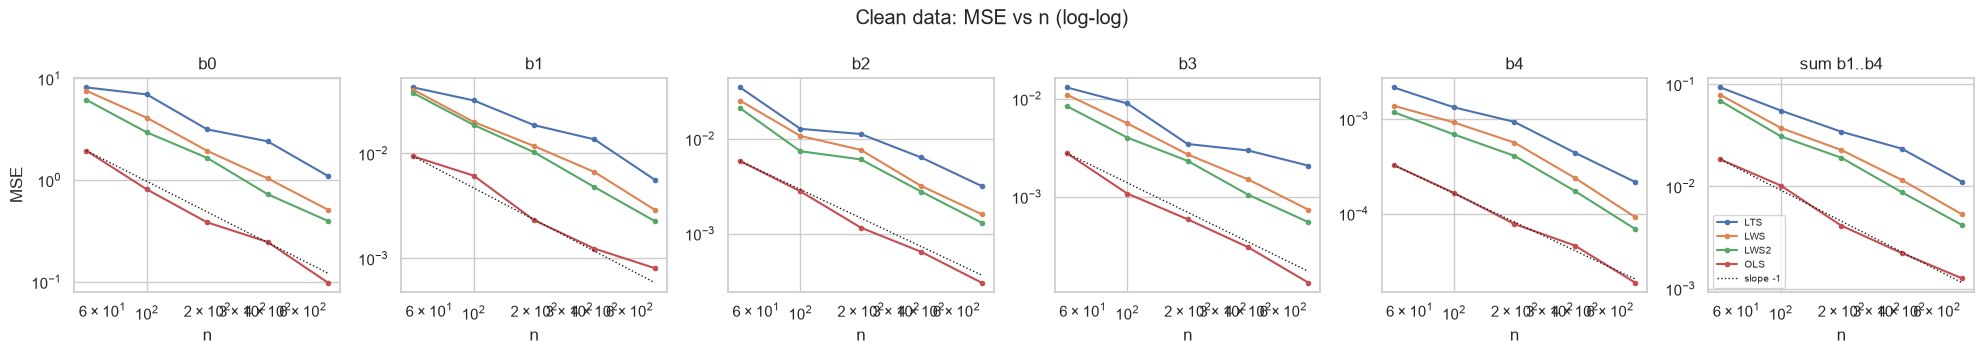

Fitted slope of log MSE(sum of slopes) vs log n: {'OLS': np.float64(-0.99), 'LTS': np.float64(-0.74), 'LWS': np.float64(-0.94), 'LWS2': np.float64(-0.99)}
Relative efficiency MSE(OLS)/MSE(method):


b0     b1     b2     b3     b4  slopes
method n                                             
LTS    50   0.238  0.220  0.167  0.213  0.152   0.198
       100  0.116  0.192  0.219  0.120  0.125   0.185
       200  0.122  0.124  0.103  0.171  0.084   0.121
       400  0.102  0.091  0.101  0.103  0.105   0.095
       800  0.089  0.144  0.095  0.064  0.087   0.114
LWS    50   0.258  0.231  0.231  0.253  0.237   0.234
       100  0.198  0.308  0.260  0.192  0.180   0.273
       200  0.198  0.197  0.151  0.218  0.138   0.182
       400  0.237  0.186  0.202  0.203  0.193   0.193
       800  0.192  0.278  0.189  0.180  0.203   0.236
LWS2   50   0.316  0.249  0.277  0.331  0.276   0.268
       100  0.275  0.328  0.377  0.269  0.241   0.330
       200  0.232  0.225  0.190  0.254  0.191   0.217
       400  0.339  0.259  0.231  0.291  0.265   0.254
       800  0.247  0.356  0.233  0.242  0.271   0.301

In [10]:
# B2
from joblib import Parallel, delayed

W1 = lambda n: weights_lws(n)              # g = 0.5, h = 0.75 -> 25 % zero weights
W2 = lambda n: weights2(n, 0.6, 0.8)       # 20 % zero weights


def one_rep(n, r, eps, kind, methods, n_starts=100, seed=2026):
    """One data set -> estimates of all methods (rows = methods)."""
    rng_ = np.random.default_rng([seed, n, r, int(1000 * eps), int(kind == 'leverage')])
    X, y = generate(n, rng_, eps=eps, kind=kind)
    out = {}
    for m in methods:
        if m == 'OLS':
            out[m] = np.linalg.lstsq(X, y, rcond=None)[0]
        elif m == 'Huber':
            out[m] = sm.RLM(y, X, M=sm.robust.norms.HuberT()).fit().params
        elif m == 'LTS':
            out[m] = lts(X, y, n_starts=n_starts, seed=r)
        elif m == 'LWS':
            out[m] = lws(X, y, W1(n), n_starts=n_starts, seed=r)
        elif m == 'LWS2':
            out[m] = lws(X, y, W2(n), n_starts=n_starts, seed=r)
    return [(m, n, r, eps, kind, *b) for m, b in out.items()]


def simulate(ns, R, eps=0.0, kind='vertical', methods=('OLS', 'LTS', 'LWS', 'LWS2')):
    rows = Parallel(n_jobs=-1)(delayed(one_rep)(n, r, eps, kind, methods) for n in ns for r in range(R))
    cols = ['method', 'n', 'r', 'eps', 'kind'] + [f'b{j}' for j in range(5)]
    return pd.DataFrame([row for rr in rows for row in rr], columns=cols)


def mse_bias(sim):
    """Empirical MSE and bias per method, eps, kind, n and coefficient."""
    est = sim[[f'b{j}' for j in range(5)]].to_numpy()
    err = pd.DataFrame(est - beta_true, columns=[f'b{j}' for j in range(5)])
    keys = sim[['kind', 'eps', 'method', 'n']].reset_index(drop=True)
    mse = pd.concat([keys, err ** 2], axis=1).groupby(['kind', 'eps', 'method', 'n']).mean()
    bias = pd.concat([keys, err], axis=1).groupby(['kind', 'eps', 'method', 'n']).mean()
    mse['slopes'] = mse[[f'b{j}' for j in range(1, 5)]].sum(axis=1)
    return mse, bias


def plot_mse(mse, title):
    """log-log MSE vs n: one panel per coefficient + the sum over the slopes."""
    cols = [f'b{j}' for j in range(5)] + ['slopes']
    fig, axes = plt.subplots(1, 6, figsize=(20, 3.6))
    m_ = mse.reset_index()
    for ax, c in zip(axes, cols):
        for meth, d in m_.groupby('method'):
            ax.plot(d['n'], d[c], 'o-', ms=3, label=meth)
        nn = np.array(sorted(m_['n'].unique()))
        ref = m_.loc[(m_.method == 'OLS') & (m_.n == nn[0]), c].iloc[0] if 'OLS' in m_.method.values else 1
        ax.plot(nn, ref * nn[0] / nn, 'k:', lw=1, label='slope -1')
        ax.set_xscale('log'); ax.set_yscale('log'); ax.set_title(c if c != 'slopes' else 'sum b1..b4'); ax.set_xlabel('n')
    axes[0].set_ylabel('MSE'); axes[-1].legend(fontsize=7)
    plt.suptitle(title); plt.tight_layout(); plt.show()


# B2: clean data
t0 = time.time()
ns = [50, 100, 200, 400, 800]
sim_clean = simulate(ns, R=100)
print(f'B2 simulation: {time.time() - t0:.0f} s')
mse0, bias0 = mse_bias(sim_clean)

print('Empirical MSE (clean data):')
display(mse0.loc['vertical', 0.0].unstack('method').round(4))
print('Empirical bias (clean data):')
display(bias0.loc['vertical', 0.0].unstack('method').round(4))
plot_mse(mse0.loc['vertical', 0.0], 'Clean data: MSE vs n (log-log)')

# slope of log MSE on log n
slope = {m: np.polyfit(np.log(ns), np.log(mse0.loc[('vertical', 0.0, m), 'slopes']), 1)[0] for m in ['OLS', 'LTS', 'LWS', 'LWS2']}
print('Fitted slope of log MSE(sum of slopes) vs log n:', {k: round(v, 2) for k, v in slope.items()})

# relative efficiency MSE(OLS) / MSE(method)
m0 = mse0.loc['vertical', 0.0]
eff = pd.concat({m: m0.loc['OLS'] / m0.loc[m] for m in ['LTS', 'LWS', 'LWS2']}, names=['method'])
print('Relative efficiency MSE(OLS)/MSE(method):')
display(eff.round(3))

**Answer B2:** ($R = 100$, `n_starts = 100`, LWS = `weights_lws` (g = 0.5, h = 0.75), LWS2 = `weights2(0.6, 0.8)`)
1. **Bias**: all estimators are practically unbiased. The bias of the slopes is of order $10^{-3}$–$10^{-2}$ and has no systematic sign. The intercept bias (e.g. LTS $-0.44$ at $n = 50$, $-0.07$ at $n = 800$) is within the Monte Carlo error, because the intercept has a large variance: the regressors have large means (e.g. $E x_4 = 20$), so $\beta_0$ is an extrapolation far away from the data.
2. **MSE vs. $n$ (log–log)**: for all methods the MSE goes to 0, and the lines are roughly parallel to the reference line with slope $-1$. The fitted slopes of $\log \mathrm{MSE}$ (sum over $\beta_1..\beta_4$) on $\log n$ are OLS $-0.99$, LWS $-0.94$, LWS2 $-0.99$, LTS $-0.74$. This is consistent with $\sqrt{n}$-consistency. LTS is noisier (non-smooth objective, only 100 random starts, so the global minimum is not always found), but its MSE still decreases (0.093 → 0.011).
3. **Relative efficiency** $\mathrm{MSE(OLS)/MSE(method)}$ (sum of slopes): LTS ≈ 0.10–0.20, LWS ≈ 0.18–0.27, LWS2 ≈ 0.22–0.33.
   - On clean data the robust estimators lose a lot: LTS (h ≈ n/2) needs roughly 5–10× more observations for the same precision as OLS (the asymptotic efficiency of LTS with 50 % coverage is only about 7 %).
   - **LWS loses less than LTS, and `weights2` loses the least.** LTS throws away about half of the observations completely. LWS gives full or partial weight to 75 % (resp. 80 %) of them, and the weights decrease smoothly, so an observation does not jump between "in" and "out" when its residual rank changes. More information is used, and the estimate is more stable.

### Task B3: contamination
Repeat B2 with **5 %, 10 % and 20 %** of contaminated observations, for at least two kinds of contamination: outliers in $y$ only, and bad leverage points (the two kinds in `generate`, or your own design; describe it). Add Huber (`sm.RLM`) to the methods.
1. Which estimators stay consistent ($\mathrm{MSE} \to 0$), which have a bias that does not vanish with $n$?
2. Which coefficients are affected by the vertical outliers? (Hint: the intercept.)
3. At which share of contamination does LWS with `weights_lws` (zero weights for the top 25 % of ranks) break down? Try 30 %.

B3 simulation: 251 s


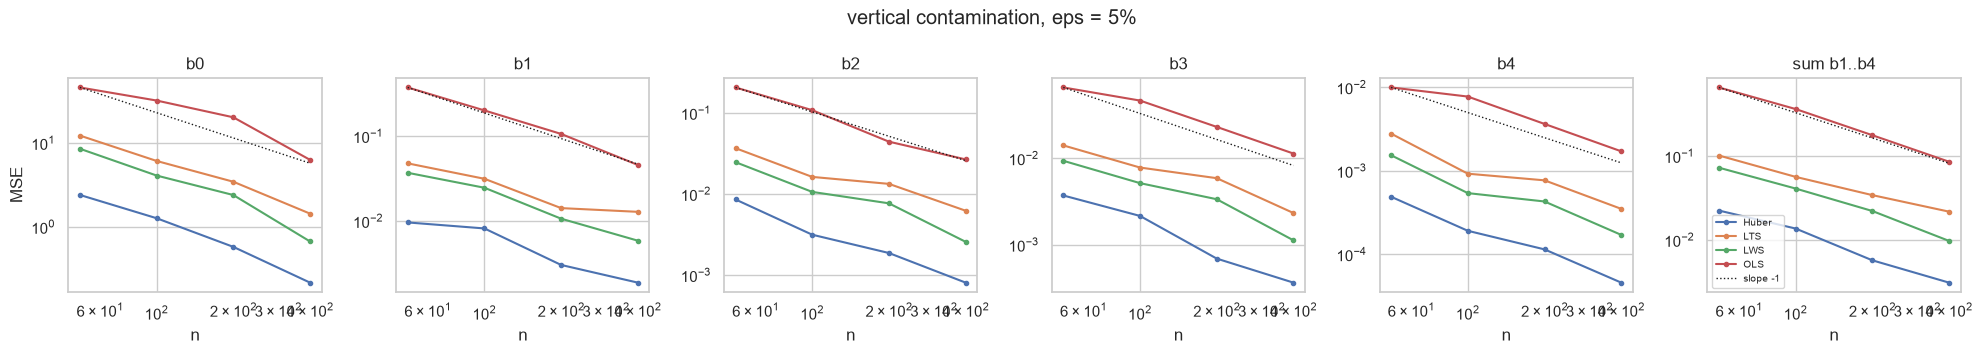

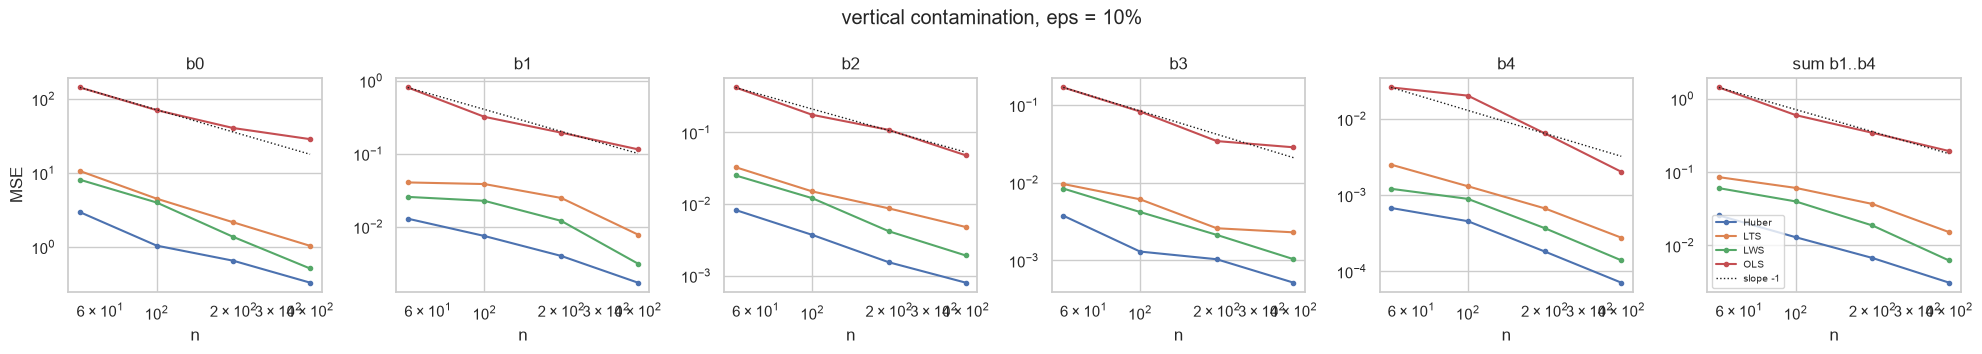

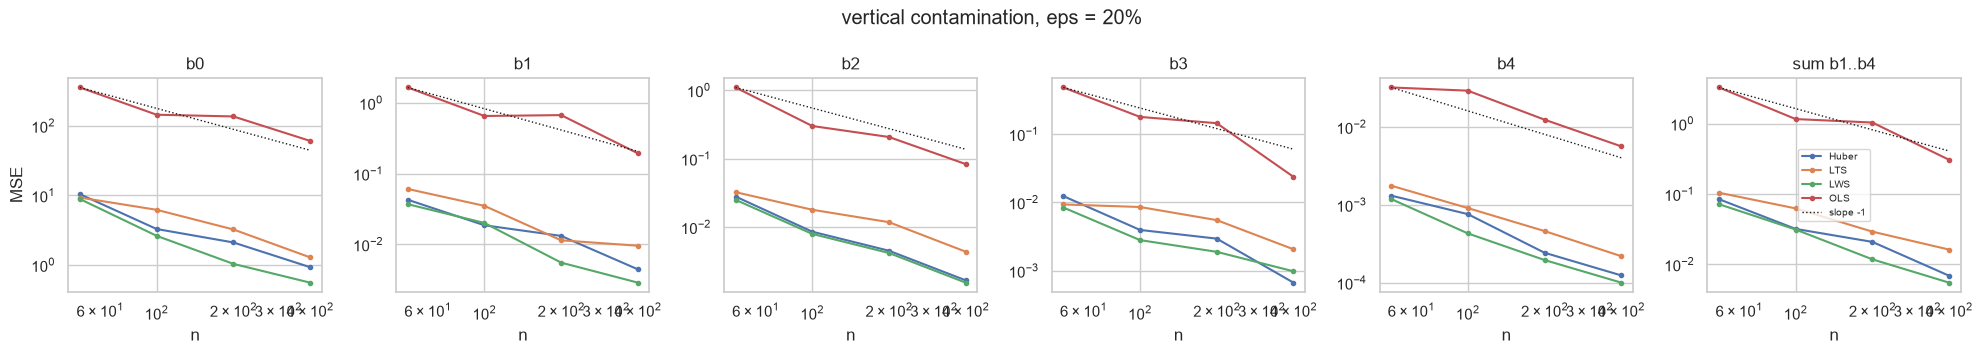

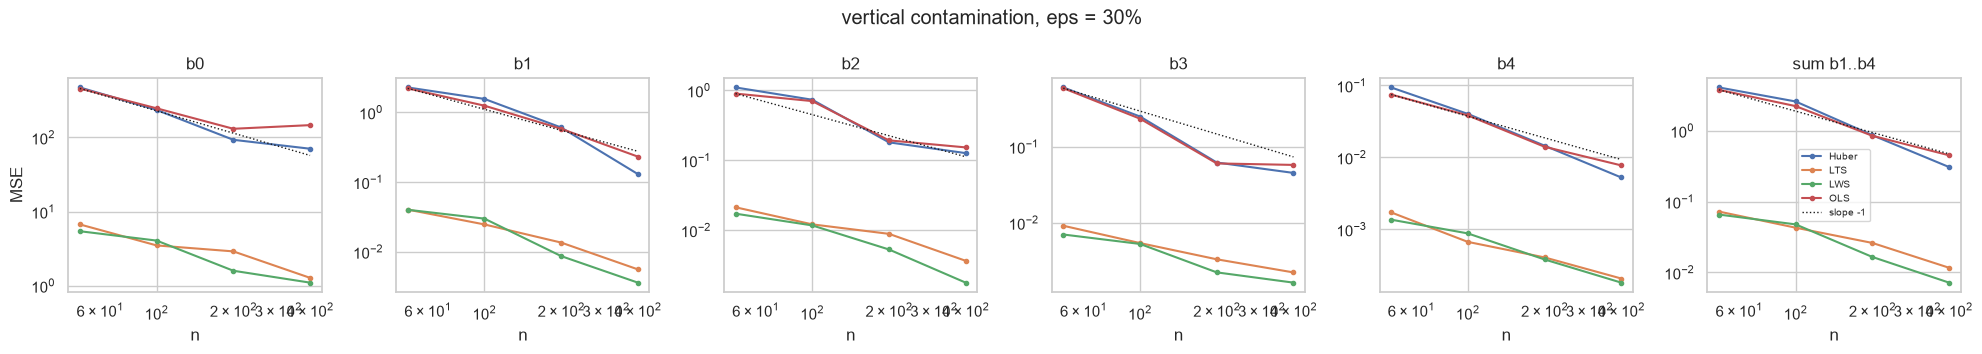

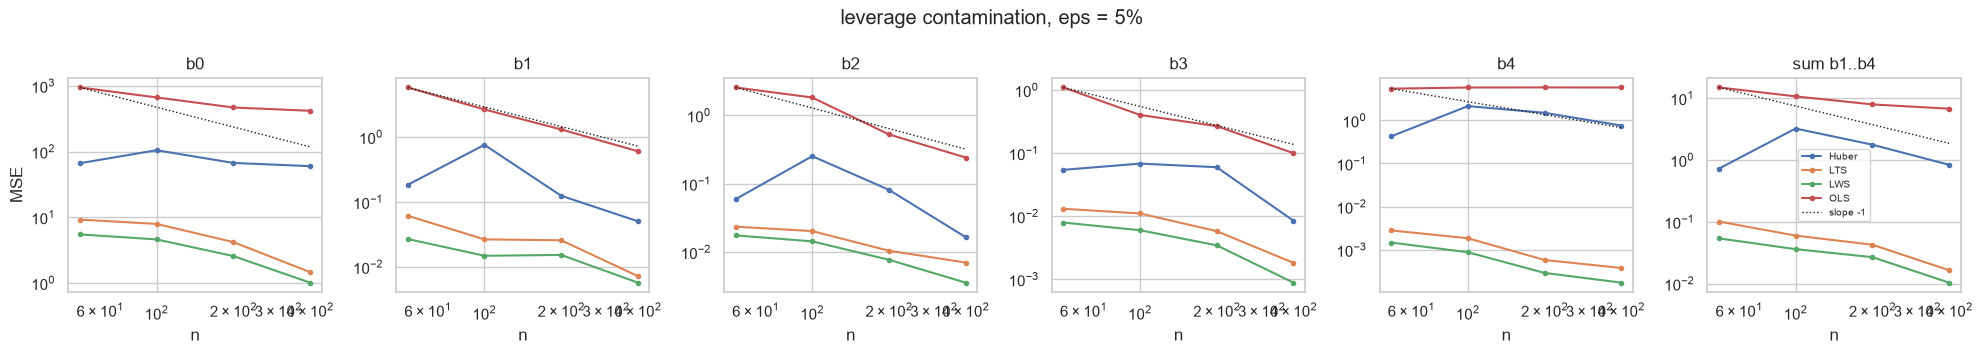

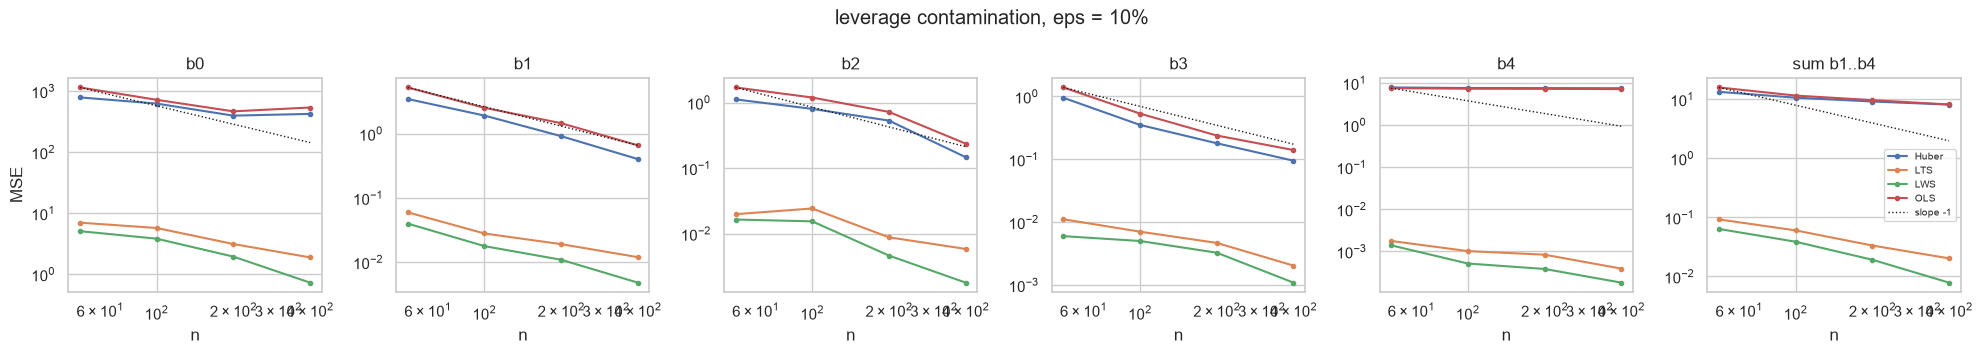

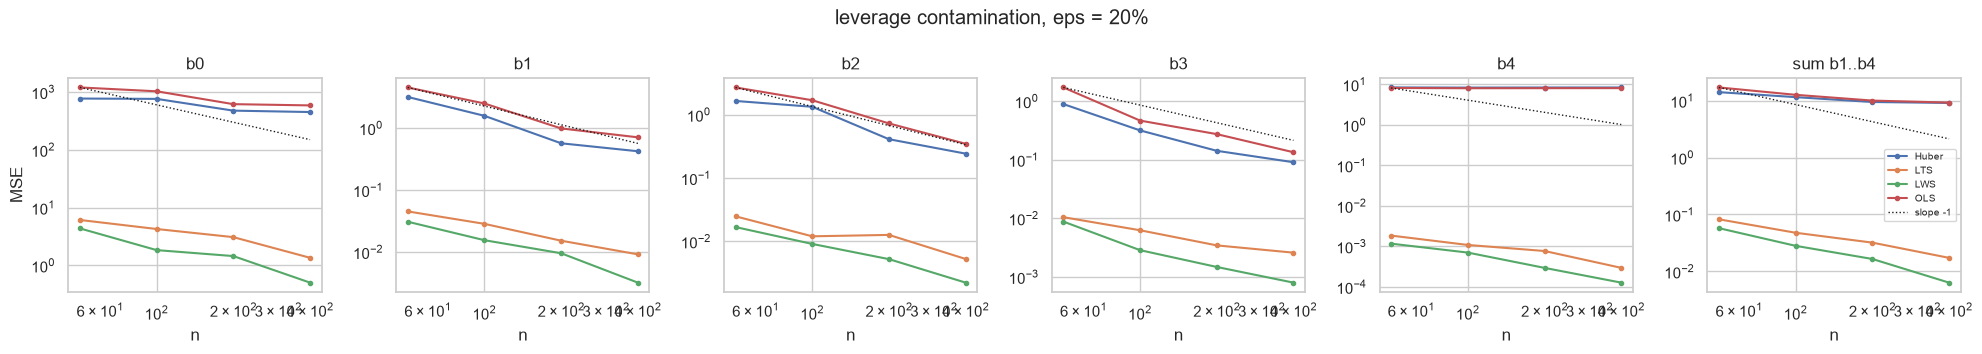

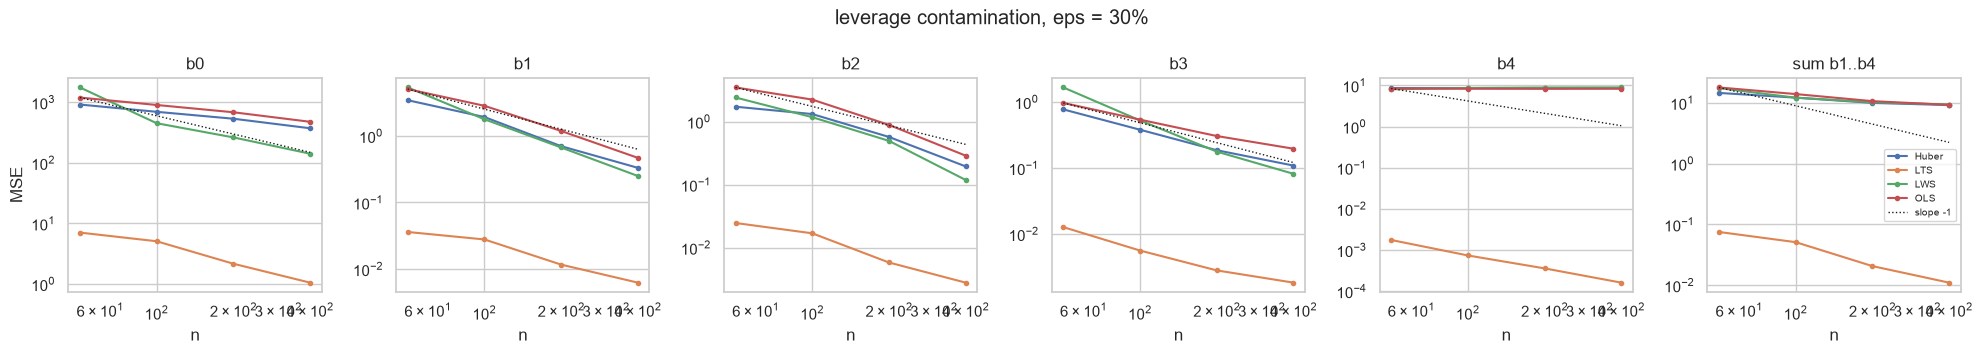

MSE of b0 (columns: n, method):


n                  50                                   400                  \
method           Huber     LTS       LWS       OLS    Huber    LTS      LWS   
kind     eps                                                                  
leverage 0.05   66.344   9.206     5.476   944.002   59.875  1.462    1.011   
         0.10  789.613   7.004     5.081  1150.149  424.075  1.888    0.729   
         0.20  770.791   6.117     4.371  1199.904  450.355  1.356    0.504   
         0.30  918.507   7.064  1759.455  1197.157  372.866  1.054  141.745   
vertical 0.05    2.395  12.215     8.508    45.755    0.216  1.434    0.668   
         0.10    2.958  10.634     8.106   143.126    0.330  1.037    0.513   
         0.20   10.378   9.280     8.838   355.367    0.926  1.282    0.555   
         0.30  473.275   6.702     5.426   457.525   70.459  1.275    1.098   

n                       
method             OLS  
kind     eps            
leverage 0.05  416.717  
         0.10  539.295  
         0.20  586.607  
         0.30  476.831  
vertical 0.05    6.273  
         0.10   28.653  
         0.20   60.609  
         0.30  146.657

MSE of slopes (columns: n, method):


n                 50                            400                     
method          Huber    LTS     LWS     OLS  Huber    LTS    LWS    OLS
kind     eps                                                            
leverage 0.05   0.722  0.101   0.054  14.882  0.835  0.016  0.010  6.737
         0.10  13.339  0.092   0.064  15.832  8.111  0.020  0.008  8.146
         0.20  14.099  0.082   0.058  17.068  9.122  0.017  0.006  9.250
         0.30  14.517  0.075  17.431  17.873  9.168  0.011  9.353  9.247
vertical 0.05   0.022  0.101   0.072   0.654  0.003  0.022  0.010  0.085
         0.10   0.026  0.085   0.060   1.425  0.003  0.015  0.006  0.193
         0.20   0.084  0.104   0.071   3.255  0.007  0.016  0.005  0.305
         0.30   4.065  0.072   0.066   3.764  0.307  0.012  0.007  0.449

Bias at n = 400:


b0     b1     b2     b3     b4
kind     eps  method                                    
leverage 0.05 Huber    4.638 -0.045 -0.017 -0.025 -0.599
              LTS      0.064 -0.011  0.002 -0.005  0.007
              LWS      0.006 -0.009  0.003 -0.001  0.004
              OLS     18.224 -0.059  0.025 -0.048 -2.405
         0.10 Huber   19.138 -0.080  0.019 -0.092 -2.732
              LTS     -0.245 -0.008  0.008  0.009  0.001
              LWS     -0.276  0.002  0.014  0.006  0.001
              OLS     21.158 -0.073 -0.020 -0.085 -2.666
         0.20 Huber   19.809 -0.150 -0.044 -0.026 -2.892
              LTS      0.060  0.016 -0.003 -0.004 -0.002
              LWS      0.052  0.004 -0.005 -0.001 -0.001
              OLS     22.268 -0.172 -0.019 -0.055 -2.839
         0.30 Huber   17.718  0.132 -0.002  0.022 -2.921
              LTS      0.107  0.008 -0.006 -0.002 -0.003
              LWS     10.075  0.126  0.029 -0.022 -2.984
              OLS     19.111  0.069  0.004  0.067 -2.880
vertical 0.05 Huber   -0.070  0.000  0.007  0.004  0.002
              LTS     -0.190 -0.007  0.007  0.004  0.004
              LWS     -0.242  0.001  0.004  0.009  0.003
              OLS      0.326  0.068  0.043  0.021  0.005
         0.10 Huber    0.241 -0.018 -0.003  0.002  0.001
              LTS     -0.156  0.001 -0.002  0.009  0.004
              LWS     -0.056 -0.006 -0.003  0.005  0.003
              OLS      3.808 -0.125 -0.039  0.006 -0.005
         0.20 Huber    0.621 -0.004 -0.001 -0.004  0.001
              LTS     -0.008 -0.010  0.000  0.003 -0.003
              LWS      0.074 -0.001 -0.007 -0.001 -0.002
              OLS      6.196 -0.044  0.018 -0.016  0.012
         0.30 Huber    5.668 -0.038  0.006 -0.034  0.005
              LTS      0.113 -0.007  0.004 -0.005 -0.002
              LWS      0.386 -0.007 -0.001 -0.005  0.001
              OLS      9.992 -0.041  0.008 -0.050  0.012

In [11]:
# B3: contamination (5, 10, 20, 30 %), two kinds, Huber added
# vertical: y_i += N(30, 5^2) for the first eps*n observations (outliers in y only, regressors untouched)
# leverage: x5_i replaced by N(80, 5^2) (typical x5 ~ 8), y_i generated from the ORIGINAL x
#           -> y is off by about 3 * (80 - 8) = 216 below the true plane: bad leverage points
t0 = time.time()
methods3 = ('OLS', 'Huber', 'LTS', 'LWS')
ns3 = [50, 100, 200, 400]          # smaller grid and R = 50 to keep the run time to a few minutes
sims = [simulate(ns3, R=50, eps=e, kind=k, methods=methods3) for k in ['vertical', 'leverage'] for e in [0.05, 0.1, 0.2, 0.3]]
sim_cont = pd.concat(sims, ignore_index=True)
print(f'B3 simulation: {time.time() - t0:.0f} s')
mse3, bias3 = mse_bias(sim_cont)

for k in ['vertical', 'leverage']:
    for e in [0.05, 0.1, 0.2, 0.3]:
        plot_mse(mse3.loc[k, e], f'{k} contamination, eps = {e:.0%}')

# compact tables: MSE of the intercept and of the sum over the slopes at n = 50 and n = 800
for c in ['b0', 'slopes']:
    t_ = mse3[c].unstack('n')[[50, 400]].unstack('method')
    print(f'MSE of {c} (columns: n, method):')
    display(t_.round(3))

print('Bias at n = 400:')
display(bias3.xs(400, level='n').round(3))

**Answer B3:** (n ∈ {50, 100, 200, 400}, R = 50, `n_starts = 100`; LWS = `weights_lws`)

Contamination design:
- **vertical**: the first $\varepsilon n$ responses get $+N(30, 5^2)$, the regressors are unchanged (outliers in $y$ only, asymmetric).
- **leverage**: the first $\varepsilon n$ values of $x_5$ are replaced by $N(80, 5^2)$ (typical $x_5 \approx 8$), while $y$ is computed from the original $x$. These are outliers and leverage points, about $3 \cdot 72 \approx 216$ below the true plane.

1. **Consistency**
   - **LTS** stays consistent in all scenarios up to 30 %: MSE of the slopes about 0.01–0.02 at $n = 400$, decreasing with $n$, bias ≈ 0.
   - **LWS** stays consistent for both kinds up to 20 %, with a smaller MSE than LTS (e.g. leverage 20 %: slopes 0.006 vs. 0.017).
   - **OLS** is not consistent under leverage contamination even at 5 %: the slope of $x_5$ has bias $\approx -2.4$ to $-2.9$ (estimated $\beta_5 \approx 0.1$–0.6 instead of 3), and the MSE of the slopes stays ≈ 7–9 at $n = 400$.
   - **Huber** behaves like OLS for outlier leverage points: bias of $\beta_5 \approx -2.7$ already at 10 % (at 5 % it is −0.6). Against vertical outliers Huber is fine up to 20 % (MSE of the slopes 0.003–0.007 at $n = 400$). Only the intercept has a small bias (up to 0.6), and it breaks down at 30 % (slopes MSE 0.31, intercept bias 5.7).
2. **Vertical outliers** affect mainly the **intercept**. For OLS the bias of $\beta_0$ grows with $\varepsilon$ (≈ 0.3, 3.8, 6.2, 10.0 at $n = 400$, theoretically $\approx 30\varepsilon$), and the MSE of $\beta_0$ stays large ($6$–$147$). The slopes of OLS remain **unbiased**, because the shift is independent of $\mathbf{x}$. They only have a larger variance, and their MSE still decreases with $n$ (e.g. 20 %: 3.26 → 0.31). The robust methods remove the intercept shift too (bias of $\beta_0$ for LTS/LWS within ±0.25 up to 20 %).
3. **Breakdown of LWS with `weights_lws`** (25 % zero weights): at **30 %** of bad (outlier) leverage points LWS **breaks down**. Bias of $\beta_5$ = −2.98, and the MSE of the slopes is 9.35, the same as OLS. LTS ($h \approx n/2$, breakdown ≈ 50 %) still works. This agrees with the theory: 30 % > 25 % zero weights, so at least 5 % of the bad points get positive weight. With 30 % *vertical* outliers LWS does not break down completely (slopes MSE 0.007), but the intercept bias grows (0.39 vs. 0.07 at 20 %). The outliers that get a positive weight sit at the end of the linear ramp, where the weights are small, and a shift only in $y$ has a bounded effect. A bad leverage point with even a small positive weight can tilt the plane arbitrarily.

### Task B4: summary
In 4–6 sentences: robustness versus efficiency, what LWS adds to LTS, when you would use OLS with diagnostics, when a robust fit, and what the weights of a robust fit tell you about the data.

**Answer B4:**
- There is a trade-off between **robustness and efficiency**. OLS is optimal on clean normal data but breaks down with a single bad point. LTS has a high breakdown point (~50 %) but on clean data its efficiency is only about 10–20 % (B2).
- **LWS** sits between them. Thanks to the smoothly decreasing weights it uses more of the information (efficiency about 1.5–2× LTS in B2). It keeps the breakdown point equal to the share of zero weights (works up to 20 %, broke at 30 % with 25 % zero weights in B3). The weight function therefore lets you choose the balance between robustness and efficiency.
- I would use **OLS with diagnostics** when the data come from a controlled setting, the residual and leverage plots show nothing suspicious, and at most single isolated outliers are possible.
- I would use a **robust fit** (LTS/LWS, ideally followed by an efficient M-step as in "Tukey from LTS") whenever groups of outliers or leverage points are possible. Masking (A2–A5) shows that leave-one-out diagnostics can fail completely.
- The **weights of a robust fit are a diagnostic tool**: observations with (near) zero weight do not follow the model of the majority. Together with the robust distances in $\mathbf{x}$ they sort the data into regular points, vertical outliers, and good and bad leverage points. They should be examined, not automatically deleted.